# Pilot demonstration: classical baselines on one MD-TOP-NFZ instance

**Input:** one instance from `data/instances/` (N targets with weights, K depots, 0-3 no-fly zones, budget B = 15 km per UAV).
**Expected output:** one closed route per UAV, each within budget, no leg crossing a no-fly zone, no target visited twice.
**Success metric:** collected reward CR (%), total length, feasibility (checker), time.
**Baselines shown:** lawnmower, greedy, OR-Tools GLS (5 s). The GNN solver is added here once it is trained.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")          # run everything from the repository root
sys.path.insert(0, os.getcwd())

import matplotlib.pyplot as plt
import pandas as pd

from src.baselines import greedy, lawnmower, ortools_top
from src.baselines.solution import timed
from src.data_gen import geometry
from src.data_gen.instance import load_instance
from src.eval import checker, metrics
from src.eval.plots import draw_solution

SPLIT, SEED = "test", 1001            # change these to look at another instance
inst = load_instance(f"data/instances/{SPLIT}/{SEED}.json")
print(f"seed {inst.seed}, topology {inst.topology}, N={inst.N}, K={inst.K}, NFZ polygons={len(inst.nfz)}, budget={inst.budget} km")
print("targets no depot can serve within budget:", inst.flags["unreachable_targets"])

seed 1001, topology corridor, N=50, K=3, NFZ polygons=3, budget=15.0 km
targets no depot can serve within budget: []


In [2]:
methods = {
    "lawnmower": (lawnmower.solve, None),
    "greedy": (greedy.solve, None),
    "ortools_5s": (ortools_top.solve, 5.0),
}
solutions, rows = {}, []
for name, (solve, limit) in methods.items():
    sol = timed(solve, inst, time_limit=limit)
    violations = checker.check(inst, sol.routes)
    solutions[name] = sol
    rows.append(metrics.instance_row(inst, name, sol, violations))
table = pd.DataFrame(rows)[["method", "CR", "CR_achievable", "L_total", "n_visited", "time_s", "feasible"]]
table.round(2)

,method,CR,CR_achievable,L_total,n_visited,time_s,feasible
0,lawnmower,45.66,45.66,44.82,22,0.00,True
1,greedy,92.83,92.83,42.63,47,0.02,True
2,ortools_5s,100.00,100.00,44.55,50,5.01,True


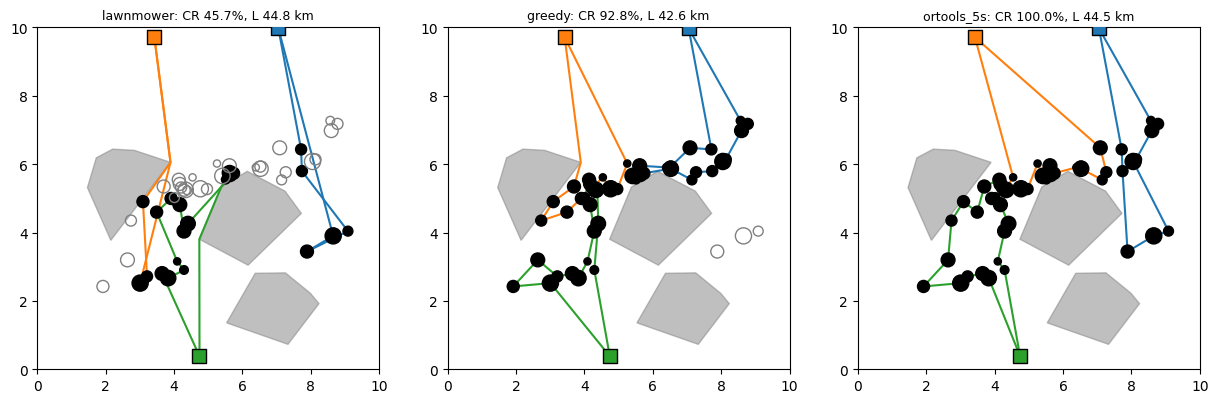

In [3]:
graph = geometry.NFZGraph(inst.points, inst.nfz)      # real obstacle-avoiding paths for drawing
fig, axes = plt.subplots(1, len(solutions), figsize=(5 * len(solutions), 5))
for ax, (name, sol) in zip(axes, solutions.items()):
    title = f"{name}: CR {metrics.cr(inst, sol.routes):.1f}%, L {metrics.total_length(inst, sol.routes):.1f} km"
    draw_solution(ax, inst, graph, sol.routes, title)
plt.show()

**Reading the plot.** Squares are depots, dots are targets sized by weight (hollow = not visited), grey polygons are no-fly zones.
Routes follow the shortest obstacle-avoiding paths, so detours around the zones are real, not straight lines.

**Next step (not done yet):** add the trained GNN + RL solver to `methods` and compare it with OR-Tools on the same instance.